In [1]:
# CELL 0: NOTEBOOK PATH SETUP
# What this cell does:
#   - Adds the project root to Python's import path so this notebook can
#     import from src/ (e.g. "from src.signals.modulations import bpsk").
#   - Turns on autoreload so edits to .py files in src/ are picked up
#     without restarting the kernel.

import sys
from pathlib import Path

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

%load_ext autoreload
%autoreload 2

print("Project root:", project_root)

Project root: c:\Users\blbon\Desktop\MyWorkspace\FYP\personal projects\rf-anomaly


signal     |  power | 99% BW (kHz) | BW / Rs
BPSK       |  1.000 |        145.5 |    1.16
QPSK       |  1.000 |        145.5 |    1.16
16-QAM     |  0.998 |        145.5 |    1.16
FSK (h=1)  |  1.000 |        276.4 |    2.21
Symbol rate Rs = 125.0 kHz | ideal RRC edge-to-edge width Rs*(1+beta) = 168.8 kHz


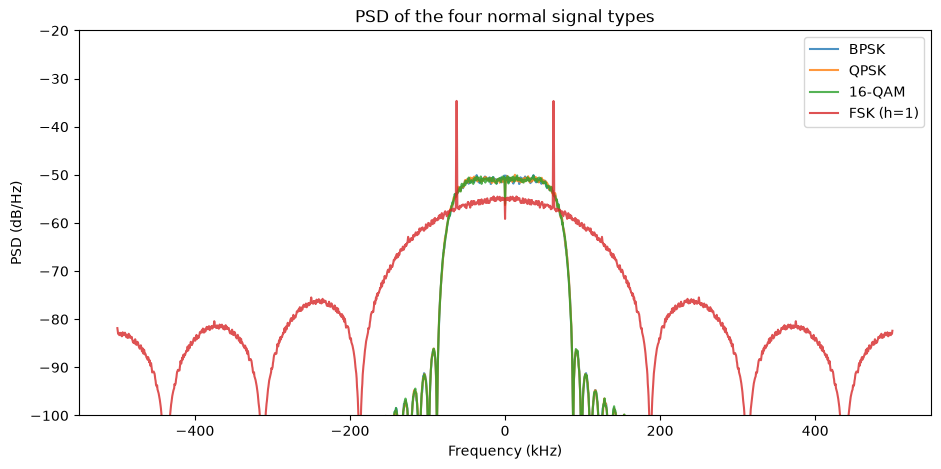

In [2]:
# CELL 1: GENERATE THE FOUR NORMAL SIGNALS AND COMPARE THEIR SPECTRA
# What this cell does:
#   - Sets fs = 1 MHz and sps = 8 samples per symbol, so the symbol rate is
#     Rs = fs/sps = 125 kHz.
#   - Generates 200,000 samples each of BPSK, QPSK, 16-QAM and binary FSK
#     (h = 1) using the functions you just tested.
#   - Estimates each PSD with Welch and plots all four on one graph.
#   - Prints each signal's average power (should be ~1.000) and its 99%
#     occupied bandwidth: the width, centred on 0 Hz, containing 99% of the power.
#   - Expected: BPSK, QPSK and 16-QAM about 145 kHz (~1.16 Rs); FSK about
#     276 kHz (~2.2 Rs). The ideal RRC edge-to-edge width Rs*(1+beta) = 168.75 kHz
#     is the width where the spectrum finally reaches zero; the 99% width is
#     smaller because power thins out near the band edges.

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

from src.signals.impairments import add_awgn
from src.signals.modulations import bpsk, qpsk, qam16, fsk, rrc_taps

fs = 1_000_000
sps = 8
rs = fs / sps
n = 200_000
rng = np.random.default_rng(42)

signals_dict = {
    "BPSK": bpsk(n, sps, rng),
    "QPSK": qpsk(n, sps, rng),
    "16-QAM": qam16(n, sps, rng),
    "FSK (h=1)": fsk(n, sps, rng),
}

def occupied_bw(f, p, frac=0.99):
    order = np.argsort(np.abs(f))
    cum = np.cumsum(p[order]) / p.sum()
    return 2 * np.abs(f[order][np.searchsorted(cum, frac)])

plt.figure(figsize=(11, 5))
print(f"{'signal':10s} | {'power':>6s} | {'99% BW (kHz)':>12s} | {'BW / Rs':>7s}")
for name, s in signals_dict.items():
    f, p = signal.welch(s, fs=fs, nperseg=2048, return_onesided=False)
    f, p = np.fft.fftshift(f), np.fft.fftshift(p)
    plt.plot(f / 1e3, 10 * np.log10(p + 1e-20), label=name, alpha=0.8)
    bw = occupied_bw(f, p)
    print(f"{name:10s} | {np.mean(np.abs(s) ** 2):6.3f} | {bw / 1e3:12.1f} | {bw / rs:7.2f}")
print(f"Symbol rate Rs = {rs / 1e3:.1f} kHz | ideal RRC edge-to-edge width Rs*(1+beta) = {rs * 1.35 / 1e3:.1f} kHz")

plt.xlabel("Frequency (kHz)")
plt.ylabel("PSD (dB/Hz)")
plt.ylim(-100, -20)
plt.title("PSD of the four normal signal types")
plt.legend()
plt.show()

BPSK   : noise std per axis after matched filter = 0.079
QPSK   : noise std per axis after matched filter = 0.079
16-QAM : noise std per axis after matched filter = 0.079
Predicted from SNR definition: sqrt(10^(-10/10) / (2*sps)) = 0.079
Effective SNR at the symbols = 19.0 dB


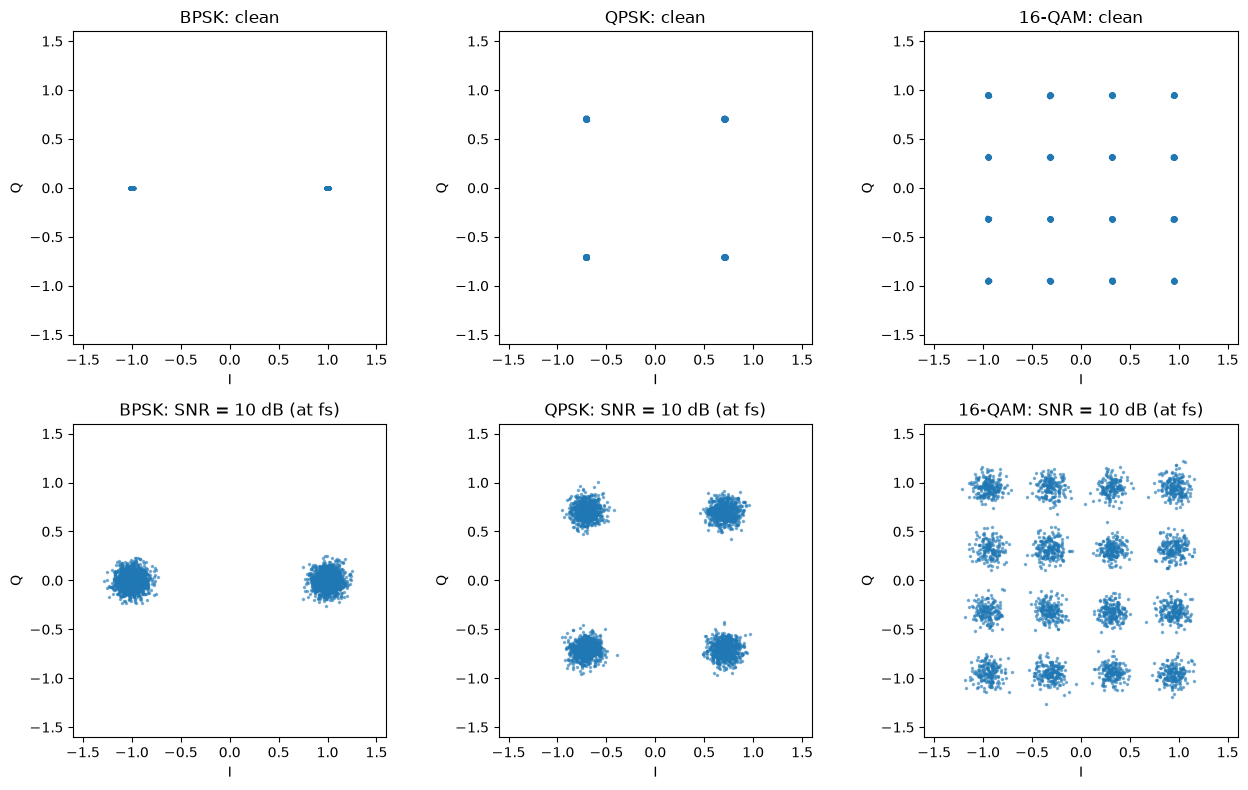

In [3]:
# CELL 2: CONSTELLATIONS, CLEAN AND NOISY
# What this cell does:
#   - Builds the receiver matched filter (the same RRC taps as the transmitter),
#     filters the signal, and samples once per symbol (every sps samples).
#     Those samples are the constellation points.
#   - Top row: clean BPSK, QPSK and 16-QAM, which should land on 2, 4 and 16
#     tight points (ideal pulse shaping leaves no inter-symbol interference).
#   - Bottom row: the same signals with noise added at SNR = 10 dB using your
#     tested add_awgn.
#   - Prints the noise standard deviation per axis measured at the matched-filter
#     output, next to the value predicted from the SNR definition.
#   - Expected: measured ~0.079 for all three, equal to the prediction.
#     The noise at the symbols is much weaker than "10 dB" suggests, because
#     SNR here is measured over the full 1 MHz band, while the signal only
#     occupies ~1/8 of it. Think about why the printed "effective SNR" is higher.

beta, span = 0.35, 10
h_rrc = rrc_taps(beta, sps, span)
delay = (len(h_rrc) - 1) // 2

def matched_filter_symbols(x):
    z = np.convolve(x, h_rrc)[delay:delay + len(x)] / np.sqrt(sps)
    return z[::sps][20:-20]          # drop edge symbols (partial filter overlap)

snr_db = 10
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for col, name in enumerate(["BPSK", "QPSK", "16-QAM"]):
    clean_sig = signals_dict[name]
    noisy_sig = add_awgn(clean_sig, snr_db, rng)
    zc = matched_filter_symbols(clean_sig)
    zn = matched_filter_symbols(noisy_sig)
    axes[0, col].plot(zc.real[:3000], zc.imag[:3000], ".", ms=3)
    axes[0, col].set_title(f"{name}: clean")
    axes[1, col].plot(zn.real[:3000], zn.imag[:3000], ".", ms=3, alpha=0.5)
    axes[1, col].set_title(f"{name}: SNR = {snr_db} dB (at fs)")
    for r in (0, 1):
        axes[r, col].set_xlim(-1.6, 1.6)
        axes[r, col].set_ylim(-1.6, 1.6)
        axes[r, col].set_aspect("equal")
        axes[r, col].set_xlabel("I")
        axes[r, col].set_ylabel("Q")
    noise_part = zn - zc
    print(f"{name:7s}: noise std per axis after matched filter = {noise_part.real.std():.3f}")

print(f"Predicted from SNR definition: sqrt(10^(-{snr_db}/10) / (2*sps)) = "
      f"{np.sqrt(10 ** (-snr_db / 10) / (2 * sps)):.3f}")
print(f"Effective SNR at the symbols = {snr_db + 10 * np.log10(sps):.1f} dB")
plt.tight_layout()
plt.show()

TX signal at symbol instants: mean |I| = 1.112, std = 0.153
After matched filter: mean |I| = 0.999, std = 0.009


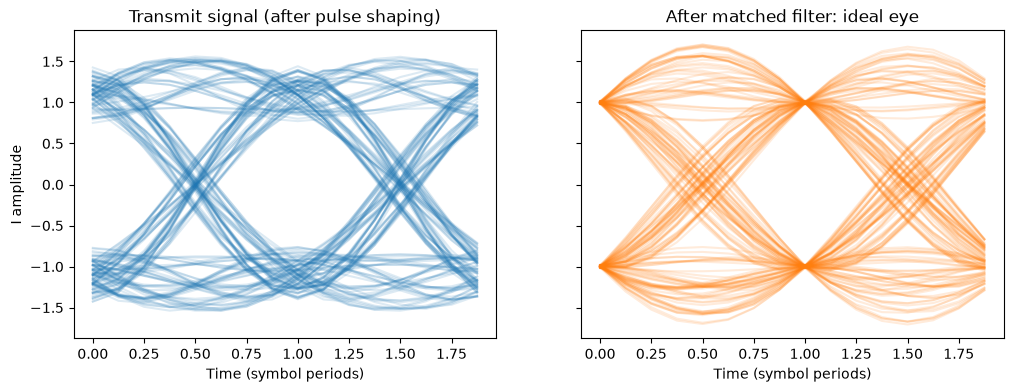

In [4]:
# CELL 3: EYE DIAGRAM OF BPSK, BEFORE AND AFTER THE MATCHED FILTER
# What this cell does:
#   - Takes the BPSK I component and cuts it into 2-symbol-long slices,
#     then overlays 400 symbols' worth of slices, which is an eye diagram.
#   - Left: the transmitted signal (one RRC filter applied). Right: after the
#     receiver's matched filter (RRC * RRC = Nyquist pulse).
#   - At t = 0 (a symbol instant), a good eye has all traces at exactly +-1.
#   - Prints the mean and spread of |I| at the symbol instant for each.
#   - Expected: transmit signal mean ~1.11, std ~0.15 (inter-symbol
#     interference); after the matched filter mean ~1.00, std ~0.01.

x = signals_dict["BPSK"]
z_mf = np.convolve(x, h_rrc)[delay:delay + len(x)] / np.sqrt(sps)

start, n_sym = 10 * sps, 400
tx_traces = x.real[start:start + n_sym * sps].reshape(-1, 2 * sps)
mf_traces = z_mf.real[start:start + n_sym * sps].reshape(-1, 2 * sps)
t_eye = np.arange(2 * sps) / sps

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].plot(t_eye, tx_traces.T, color="C0", alpha=0.15)
axes[0].set_title("Transmit signal (after pulse shaping)")
axes[1].plot(t_eye, mf_traces.T, color="C1", alpha=0.15)
axes[1].set_title("After matched filter: ideal eye")
for a in axes:
    a.set_xlabel("Time (symbol periods)")
axes[0].set_ylabel("I amplitude")

print(f"TX signal at symbol instants: mean |I| = {np.abs(tx_traces[:, 0]).mean():.3f}, "
      f"std = {np.abs(tx_traces[:, 0]).std():.3f}")
print(f"After matched filter: mean |I| = {np.abs(mf_traces[:, 0]).mean():.3f}, "
      f"std = {np.abs(mf_traces[:, 0]).std():.3f}")
plt.show()

scenario                         | anomaly samples | power in window vs outside
Narrowband tone                  |            6000 |                    1.73 dB
Wideband noise burst             |            6000 |                    1.73 dB
Chirp                            |            6000 |                    1.70 dB
Frequency hopping                |            6000 |                    1.70 dB
Carrier drift                    |            6000 |                    0.01 dB
Modulation swap (QPSK->16QAM)    |            6000 |                    0.02 dB


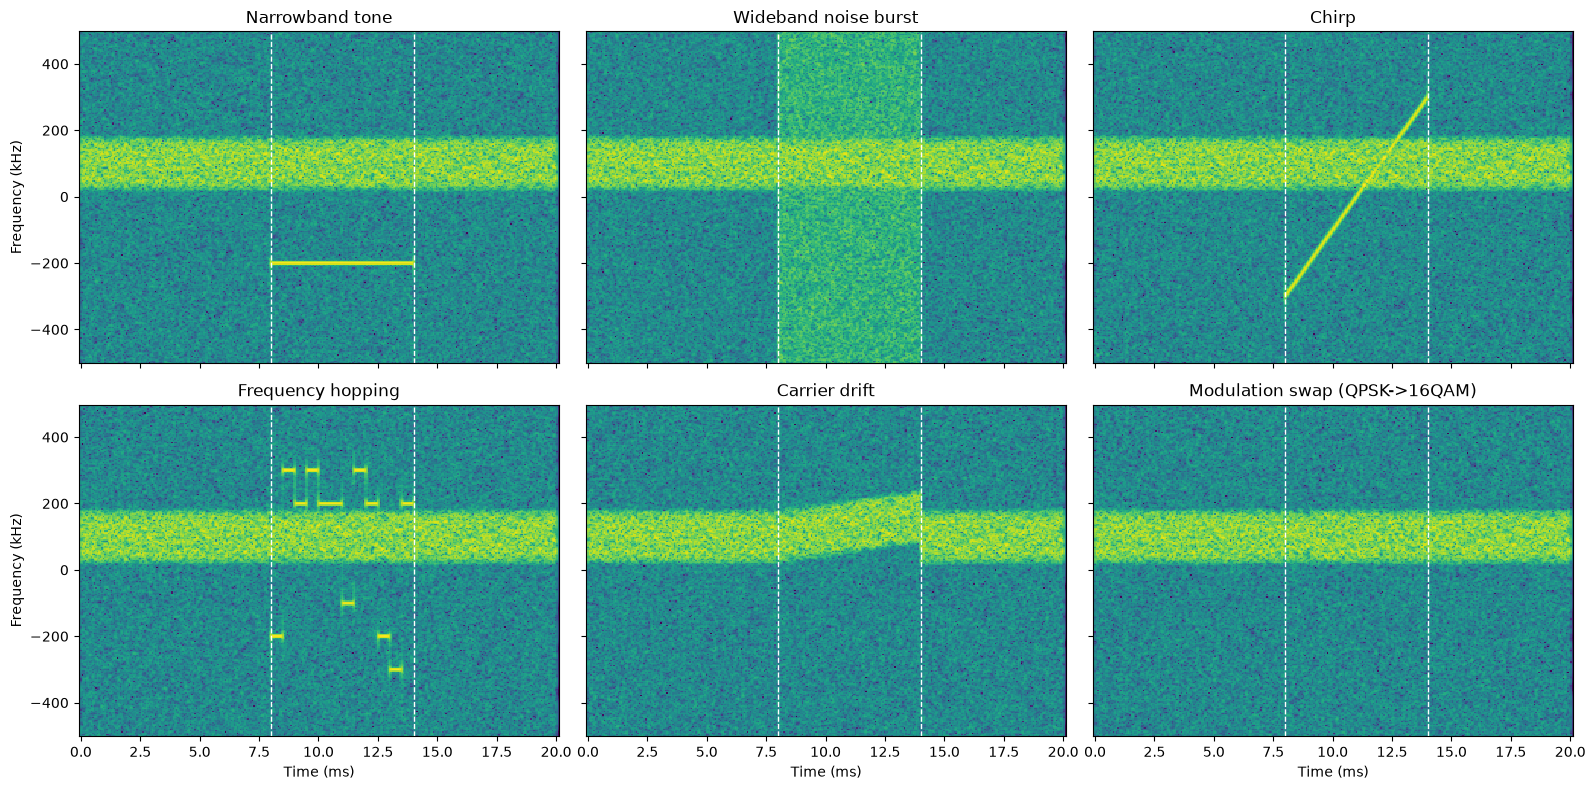

In [5]:
# CELL 4: INJECT SIX ANOMALY FAMILIES INTO A NORMAL QPSK SIGNAL
# What this cell does:
#   - Normal signal: QPSK shifted to a +100 kHz carrier, 20 ms long, 8 samples/symbol.
#   - Anomaly window: samples 8,000-14,000 (8 ms to 14 ms), 6,000 samples.
#   - Six scenarios, each built into the CLEAN signal, with noise added last
#     at SNR = 15 dB measured against the normal signal (ref_power = 1.0):
#       1) narrowband tone at -200 kHz           (added, -3 dB relative to the normal signal)
#       2) wideband noise burst                  (added, -3 dB)
#       3) chirp sweeping -300 to +300 kHz       (added, -3 dB)
#       4) frequency hopping over 5 frequencies  (added, -3 dB)
#       5) carrier drift: the normal QPSK itself drifts upward by 60 kHz (replaced, 0 dB)
#       6) modulation swap: 16-QAM at the same carrier, rate and power as the QPSK
#          (replaced, 0 dB)
#   - Plots one spectrogram per scenario on the SAME colour scale, with dashed
#     lines marking the anomaly window.
#   - Prints the average power inside vs outside the window.
#   - Expected: scenarios 1-4 about +1.7 dB (they add power); scenarios 5 and 6
#     about 0.0 dB (same power as normal signal).

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

from src.signals.impairments import add_awgn, apply_freq_offset
from src.signals.modulations import qpsk, qam16
from src.signals.anomalies import tone, wideband_noise, chirp, hopping, apply_freq_drift, inject

fs = 1_000_000
sps = 8
n = 20_000
start, length = 8_000, 6_000
snr_db = 15
rng = np.random.default_rng(7)

base = apply_freq_offset(qpsk(n, sps, rng), 100_000, fs)

def build(name):
    if name == "Narrowband tone":
        return inject(base, tone(length, fs, -200e3), start, rel_power_db=-3, mode="add")
    if name == "Wideband noise burst":
        return inject(base, wideband_noise(length, rng), start, rel_power_db=-3, mode="add")
    if name == "Chirp":
        return inject(base, chirp(length, fs, -300e3, 300e3), start, rel_power_db=-3, mode="add")
    if name == "Frequency hopping":
        hop = hopping(length, fs, [-300e3, -200e3, -100e3, 200e3, 300e3], dwell=500, rng=rng)
        return inject(base, hop, start, rel_power_db=-3, mode="add")
    if name == "Carrier drift":
        drifted = apply_freq_drift(base[start:start + length], fs, 60_000)
        return inject(base, drifted, start, rel_power_db=0, mode="replace")
    if name == "Modulation swap (QPSK->16QAM)":
        swap = apply_freq_offset(qam16(length, sps, rng), 100_000, fs)
        return inject(base, swap, start, rel_power_db=0, mode="replace")

names = ["Narrowband tone", "Wideband noise burst", "Chirp", "Frequency hopping",
         "Carrier drift", "Modulation swap (QPSK->16QAM)"]

SFT = signal.ShortTimeFFT(signal.get_window("hann", 256), hop=64, fs=fs,
                          fft_mode="centered", scale_to="psd")
scenarios = {}
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey=True)
print(f"{'scenario':32s} | {'anomaly samples':>15s} | {'power in window vs outside':>26s}")
for ax, name in zip(axes.ravel(), names):
    clean, mask = build(name)
    noisy = add_awgn(clean, snr_db, rng, ref_power=1.0)
    scenarios[name] = (noisy, mask)
    S_db = 10 * np.log10(SFT.spectrogram(noisy) + 1e-20)
    ax.pcolormesh(SFT.t(n) * 1e3, SFT.f / 1e3, S_db, shading="auto", vmin=-110, vmax=-40)
    ax.axvline(start / fs * 1e3, color="w", ls="--", lw=1)
    ax.axvline((start + length) / fs * 1e3, color="w", ls="--", lw=1)
    ax.set_title(name)
    ratio_db = 10 * np.log10(np.mean(np.abs(noisy[mask]) ** 2) / np.mean(np.abs(noisy[~mask]) ** 2))
    print(f"{name:32s} | {mask.sum():15d} | {ratio_db:23.2f} dB")
for ax in axes[1]:
    ax.set_xlabel("Time (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("Frequency (kHz)")
plt.tight_layout()
plt.show()

In [6]:
# CELL 5: RUN THE NAIVE PHASE-1 DETECTOR ON ALL SIX SCENARIOS
# What this cell does:
#   - Reuses the Phase-1 method: background = median over time of each
#     frequency row; flag pixels more than 11.23 dB above it (threshold from
#     the theoretical p_fa = 1e-4 per pixel).
#   - "Slices detected" = fraction of time slices INSIDE the anomaly window
#     (0.2 ms in from each edge) where at least one pixel is flagged.
#   - "False-alarm rate" = fraction of flagged pixels in slices clearly OUTSIDE
#     the anomaly (more than 0.3 ms from it) and away from the recording edges.
#   - Expected approx: tone, noise burst, hopping ~100%; chirp and drift
#     ~80%; modulation swap ~5% (about chance level).
#   - False-alarm rates should be near 1e-4 (they can differ by a few times,
#     as the median is also pulled by the anomaly itself).
#   - Needs variables from Cell 4: scenarios, names, SFT, fs, n, start, length.

p_fa = 1e-4
thr_db = 10 * np.log10(-np.log(p_fa) / np.log(2))
t_ax = SFT.t(n)
edge = 0.3e-3
t0, t1 = start / fs, (start + length) / fs
inside_cols = (t_ax >= t0 + 0.2e-3) & (t_ax <= t1 - 0.2e-3)
outside_cols = (((t_ax < t0 - edge) | (t_ax > t1 + edge))
                & (t_ax > edge) & (t_ax < n / fs - edge))

print(f"Threshold: {thr_db:.2f} dB above the median background (p_fa = {p_fa})")
print(f"{'scenario':32s} | {'slices detected':>15s} | {'false-alarm rate (clean slices)':>31s}")
for name in names:
    noisy, mask = scenarios[name]
    S_db = 10 * np.log10(SFT.spectrogram(noisy) + 1e-20)
    resid = S_db - np.median(S_db, axis=1, keepdims=True)
    flagged = resid > thr_db
    det = flagged[:, inside_cols].any(axis=0).mean()
    far = flagged[:, outside_cols].mean()
    print(f"{name:32s} | {det * 100:14.1f}% | {far:31.2e}")

Threshold: 11.23 dB above the median background (p_fa = 0.0001)
scenario                         | slices detected | false-alarm rate (clean slices)
Narrowband tone                  |          100.0% |                        1.37e-04
Wideband noise burst             |          100.0% |                        0.00e+00
Chirp                            |           82.8% |                        7.81e-05
Frequency hopping                |          100.0% |                        9.77e-05
Carrier drift                    |           81.6% |                        3.71e-04
Modulation swap (QPSK->16QAM)    |            5.7% |                        1.37e-04


family       | normal | sps | carrier kHz | SNR dB |  start | length | rel dB | extra
normal       |   bpsk |  16 |        -9.8 |    6.1 |      - |      - |    nan | 
tone         |    fsk |   8 |        98.6 |   -3.5 |   6785 |   9822 |   -6.9 | {'freq_hz': -130316.86167546152}
noise_burst  |  qam16 |  16 |       -97.7 |    1.4 |   9312 |   7221 |   -6.7 | {}
chirp        |  qam16 |   8 |      -143.1 |   -3.1 |   7976 |  11333 |   -5.4 | {'f_start_hz': 289763.32103472354, 'f_stop_hz': -302197.133734282}
hopping      |   bpsk |  10 |       -63.4 |   18.2 |  16103 |   9715 |   -2.2 | {'n_freqs': 5, 'dwell': 500}
drift        |   bpsk |  10 |        66.7 |   -0.8 |  10607 |  10692 |    0.0 | {'total_drift_hz': -22858.311973956206}
mod_swap     |   qpsk |  16 |        53.2 |   20.4 |  19996 |   6666 |    0.0 | {'swapped_to': 'bpsk'}


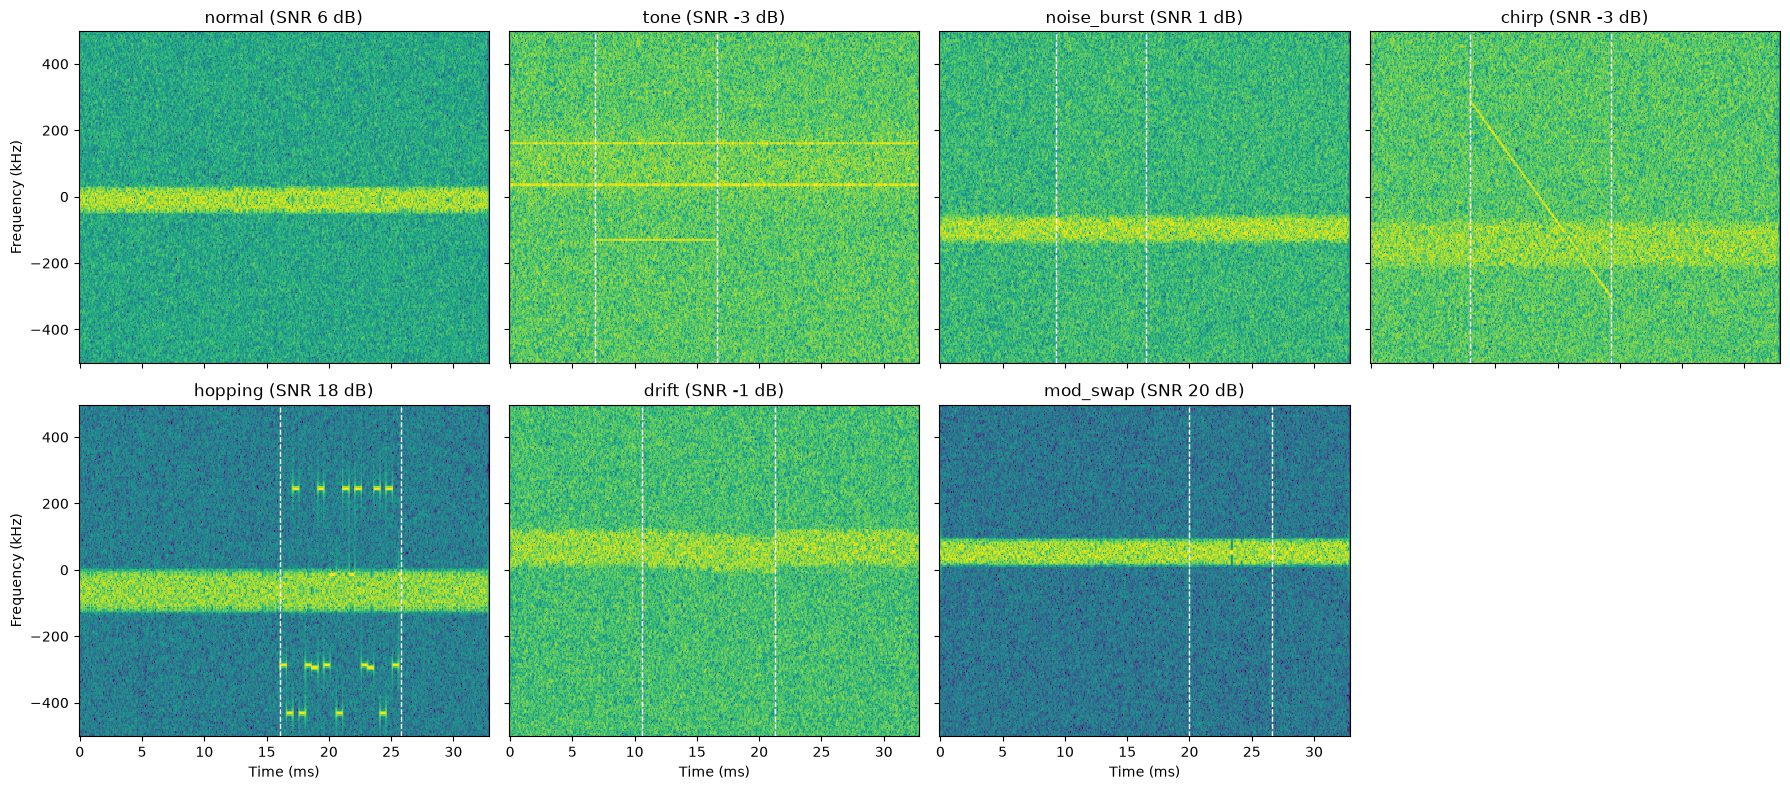

Streamed first chunk: (4096,) | fs = 1000000


In [7]:
# CELL 6: ONE RANDOM EXAMPLE OF EVERY FAMILY, THROUGH THE REAL GENERATOR
# What this cell does:
#   - Calls make_recording once per family (plus one normal-only recording)
#     with a fixed seed, so you can see what the dataset will look like.
#   - Plots each spectrogram on the same colour scale with dashed lines at the
#     anomaly start and end (the ground-truth label).
#   - Prints the parameters that were randomly drawn for each recording
#     (normal type, samples per symbol, carrier, SNR, anomaly start, length,
#     relative power and family-specific parameters).
#   - Expected: some anomalies are easy to see, but some are faint or invisible
#     (low SNR, low relative power, or mod_swap). That is intentional.
#   - Finally streams the first 4,096 samples through SimulatedSource.read()
#     to show the IQSource interface. Expected: shape (4096,) and fs = 1000000.

import numpy as np
import matplotlib.pyplot as plt

from src.data.splits import build_split
from src.dsp.spectrum import spectrogram_db
from src.dsp.windowing import collect_windows
from src.sources.simulated import FAMILIES, make_recording, SimulatedSource

rng = np.random.default_rng(2026)
examples = [make_recording(rng, fam) for fam in [None, *FAMILIES]]

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
print(f"{'family':12s} | {'normal':>6s} | {'sps':>3s} | {'carrier kHz':>11s} | {'SNR dB':>6s} | "
      f"{'start':>6s} | {'length':>6s} | {'rel dB':>6s} | extra")
for ax, rec in zip(axes.ravel(), examples):
    m = rec.meta
    t, f, s_db = spectrogram_db(rec.iq, rec.fs)
    ax.pcolormesh(t * 1e3, f / 1e3, s_db, shading="auto", vmin=-110, vmax=-40)
    if rec.mask.any():
        a, b = np.flatnonzero(rec.mask)[[0, -1]]
        ax.axvline(a / rec.fs * 1e3, color="w", ls="--", lw=1)
        ax.axvline((b + 1) / rec.fs * 1e3, color="w", ls="--", lw=1)
    ax.set_title(f"{m['family']} (SNR {m['snr_db']:.0f} dB)")
    print(f"{m['family']:12s} | {m['normal_type']:>6s} | {m['sps']:3d} | {m['carrier_hz'] / 1e3:11.1f} | "
          f"{m['snr_db']:6.1f} | {m.get('start', '-'):>6} | {m.get('length', '-'):>6} | "
          f"{m.get('rel_power_db', float('nan')):6.1f} | {m.get('params', '')}")
axes.ravel()[-1].axis("off")
for ax in axes[1]:
    ax.set_xlabel("Time (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("Frequency (kHz)")
plt.tight_layout()
plt.show()

src = SimulatedSource(examples[1])
first = src.read(4096)
print("Streamed first chunk:", first.shape, "| fs =", src.fs)

In [8]:
# CELL 7: BUILD SMALL VERSIONS OF THE THREE SPLITS AND INSPECT THEIR LABELS
# What this cell does:
#   - Builds a small train (28 recordings), validation (30) and test (70)
#     split with build_split, then cuts each into 4096-sample windows with
#     hop 2048 (15 windows per recording).
#   - Prints per split: total windows, and counts of normal (0), anomalous (1)
#     and ambiguous (-1) windows, plus which families appear.
#   - For the test split, prints the same counts per family.
#   - Expected: windows = 420 / 450 / 1050; train has 0 anomalous windows;
#     val families = normal, tone, noise_burst; test has all 7; each anomaly
#     family has exactly 20 ambiguous windows (2 per recording x 10
#     recordings), and about 40-55 anomalous windows.
#   - Prints the memory of the test windows array. We will generate larger
#     splits later and store them on disk.

WIN, HOP = 4096, 2048
print(f"{'split':5s} | {'recs':>4s} | {'windows':>7s} | {'normal':>6s} | {'anomalous':>9s} | "
      f"{'ambiguous':>9s} | families")
for split, n_rec in [("train", 28), ("val", 30), ("test", 70)]:
    recs = build_split(split, n_rec)
    d = collect_windows(recs, WIN, HOP)
    y = d["y"]
    fams = sorted({r.meta["family"] for r in recs})
    print(f"{split:5s} | {n_rec:4d} | {len(y):7d} | {(y == 0).sum():6d} | {(y == 1).sum():9d} | "
          f"{(y == -1).sum():9d} | {fams}")
    if split == "test":
        print("\nTest windows by family (normal / anomalous / ambiguous):")
        for fam in sorted(set(d["family"])):
            yy = y[d["family"] == fam]
            print(f"  {fam:12s} {(yy == 0).sum():4d} / {(yy == 1).sum():4d} / {(yy == -1).sum():4d}")
        print(f"\nTest SNR range: {d['snr_db'].min():.1f} to {d['snr_db'].max():.1f} dB")
print("Memory of the test windows array (MB):", round(d["x"].nbytes / 1e6, 1))

split | recs | windows | normal | anomalous | ambiguous | families
train |   28 |     420 |    420 |         0 |         0 | ['normal']
val   |   30 |     450 |    315 |        95 |        40 | ['noise_burst', 'normal', 'tone']
test  |   70 |    1050 |    637 |       293 |       120 | ['chirp', 'drift', 'hopping', 'mod_swap', 'noise_burst', 'normal', 'tone']

Test windows by family (normal / anomalous / ambiguous):
  chirp          82 /   48 /   20
  drift          78 /   52 /   20
  hopping        79 /   51 /   20
  mod_swap       86 /   44 /   20
  noise_burst    78 /   52 /   20
  normal        150 /    0 /    0
  tone           84 /   46 /   20

Test SNR range: -4.9 to 23.7 dB
Memory of the test windows array (MB): 34.4
